In [1]:
# !uv pip install -U pip setuptools wheel

In [2]:
# !uv pip uninstall adversarial-robustness-toolbox
# #!pip install adversarial-robustness-toolbox
# !uv pip install --ignore-installed --no-deps adversarial-robustness-toolbox==1.20.1

In [13]:
from pathlib import Path
import os

BASE_PATH = Path(r"\\100.x.x.x\linux_home") / "p3"
BASE_PATH.mkdir(parents=True, exist_ok=True)

os.chdir(BASE_PATH)

print(f"dir: {Path.cwd()}")
print(f"data: {BASE_PATH}")


dir: \\100.x.x.x\linux_home\p3
data: \\100.x.x.x\linux_home\p3


In [3]:
import art
print(art.__version__)

F:\remote-python\envs\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1.20.1


In [4]:
import sys
print(sys.version)

3.12.9 (main, Mar 17 2025, 21:06:20) [MSC v.1943 64 bit (AMD64)]


In [5]:
import sys
import art
import torch

print("Python:", sys.version)
print("ART:", art.__version__)
print("PyTorch:", torch.__version__)

Python: 3.12.9 (main, Mar 17 2025, 21:06:20) [MSC v.1943 64 bit (AMD64)]
ART: 1.20.1
PyTorch: 2.6.0+cu124


In [6]:
from art.attacks.poisoning import FeatureCollisionAttack
print("OK")

OK


In [7]:
import numpy as np
from art.utils import load_dataset

# Cargar CIFAR-10
(x_train, y_train), (x_test, y_test), min_, max_ = load_dataset("cifar10")

# Convertir a formato PyTorch (N,C,H,W)
x_train = np.transpose(x_train, (0, 3, 1, 2)).astype(np.float32)
x_test = np.transpose(x_test, (0, 3, 1, 2)).astype(np.float32)

# Trabajaremos con un subconjunto para acelerar la práctica
x_train = x_train[:1000]
y_train = y_train[:1000]

x_test = x_test[:1000]
y_test = y_test[:1000]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test :", x_test.shape)
print("y_test :", y_test.shape)

print("min =", min_)
print("max =", max_)

x_train: (1000, 3, 32, 32)
y_train: (1000, 10)
x_test : (1000, 3, 32, 32)
y_test : (1000, 10)
min = 0.0
max = 1.0


In [14]:
from urllib.request import urlretrieve

MODEL_PATH = BASE_PATH / "resnet18.pt"
MODEL_URL = "https://www.dropbox.com/s/ljkld6opyruvn5u/resnet18.pt?dl=1"

if not MODEL_PATH.exists():
    urlretrieve(MODEL_URL, MODEL_PATH)

print(f"Modelo guardado en: {MODEL_PATH.resolve()}")

Modelo guardado en: \\100.x.x.x\linux_home\p3\resnet18.pt


In [17]:
print(f"model size: {MODEL_PATH.stat().st_size / (1024 ** 2)} MiB")

model size: 42.701165199279785 MiB


In [19]:
import torch

state_dict = torch.load(
    "resnet18.pt",
    map_location="cpu"
)

print(type(state_dict))
print(len(state_dict))

<class 'collections.OrderedDict'>
122


In [20]:
import torch
import torch.nn as nn
import os

# Model Definition and pretrained model pulled from:
# https://github.com/huyvnphan/PyTorch_CIFAR10

__all__ = [
    "ResNet",
    "resnet18",
    "resnet34",
    "resnet50",
]


def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    """3x3 convolution with padding"""
    return nn.Conv2d(
        in_planes,
        out_planes,
        kernel_size=3,
        stride=stride,
        padding=dilation,
        groups=groups,
        bias=False,
        dilation=dilation,
    )


def conv1x1(in_planes, out_planes, stride=1):
    """1x1 convolution"""
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(
        self,
        inplanes,
        planes,
        stride=1,
        downsample=None,
        groups=1,
        base_width=64,
        dilation=1,
        norm_layer=None,
    ):
        super(BasicBlock, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        if groups != 1 or base_width != 64:
            raise ValueError("BasicBlock only supports groups=1 and base_width=64")
        if dilation > 1:
            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = norm_layer(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = norm_layer(planes)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out


class Bottleneck(nn.Module):
    expansion = 4

    def __init__(
        self,
        inplanes,
        planes,
        stride=1,
        downsample=None,
        groups=1,
        base_width=64,
        dilation=1,
        norm_layer=None,
    ):
        super(Bottleneck, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        width = int(planes * (base_width / 64.0)) * groups
        # Both self.conv2 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv1x1(inplanes, width)
        self.bn1 = norm_layer(width)
        self.conv2 = conv3x3(width, width, stride, groups, dilation)
        self.bn2 = norm_layer(width)
        self.conv3 = conv1x1(width, planes * self.expansion)
        self.bn3 = norm_layer(planes * self.expansion)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out


class ResNet(nn.Module):
    def __init__(
        self,
        block,
        layers,
        num_classes=10,
        zero_init_residual=False,
        groups=1,
        width_per_group=64,
        replace_stride_with_dilation=None,
        norm_layer=None,
    ):
        super(ResNet, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 64
        self.dilation = 1
        if replace_stride_with_dilation is None:
            # each element in the tuple indicates if we should replace
            # the 2x2 stride with a dilated convolution instead
            replace_stride_with_dilation = [False, False, False]
        if len(replace_stride_with_dilation) != 3:
            raise ValueError(
                "replace_stride_with_dilation should be None "
                "or a 3-element tuple, got {}".format(replace_stride_with_dilation)
            )
        self.groups = groups
        self.base_width = width_per_group

        # CIFAR10: kernel_size 7 -> 3, stride 2 -> 1, padding 3->1
        self.conv1 = nn.Conv2d(
            3, self.inplanes, kernel_size=3, stride=1, padding=1, bias=False
        )
        # END

        self.bn1 = norm_layer(self.inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(
            block, 128, layers[1], stride=2, dilate=replace_stride_with_dilation[0]
        )
        self.layer3 = self._make_layer(
            block, 256, layers[2], stride=2, dilate=replace_stride_with_dilation[1]
        )
        self.layer4 = self._make_layer(
            block, 512, layers[3], stride=2, dilate=replace_stride_with_dilation[2]
        )
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512 * block.expansion, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # Zero-initialize the last BN in each residual branch,
        # so that the residual branch starts with zeros, and each residual block behaves like an identity.
        # This improves the model by 0.2~0.3% according to https://arxiv.org/abs/1706.02677
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, Bottleneck):
                    nn.init.constant_(m.bn3.weight, 0)
                elif isinstance(m, BasicBlock):
                    nn.init.constant_(m.bn2.weight, 0)

    def _make_layer(self, block, planes, blocks, stride=1, dilate=False):
        norm_layer = self._norm_layer
        downsample = None
        previous_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                norm_layer(planes * block.expansion),
            )

        layers = []
        layers.append(
            block(
                self.inplanes,
                planes,
                stride,
                downsample,
                self.groups,
                self.base_width,
                previous_dilation,
                norm_layer,
            )
        )
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(
                block(
                    self.inplanes,
                    planes,
                    groups=self.groups,
                    base_width=self.base_width,
                    dilation=self.dilation,
                    norm_layer=norm_layer,
                )
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = x.reshape(x.size(0), -1)
        x = self.fc(x)

        return x


def _resnet(arch, block, layers, pretrained, progress, device, **kwargs):
    model = ResNet(block, layers, **kwargs)
    if pretrained:
        state_dict = torch.load(
            'resnet18.pt', map_location=device
        )
        model.load_state_dict(state_dict)
    return model


def resnet18(pretrained=False, progress=True, device="cpu", **kwargs):
    """Constructs a ResNet-18 model.
    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet(
        "resnet18", BasicBlock, [2, 2, 2, 2], pretrained, progress, device, **kwargs
    )

classifier_model = resnet18(pretrained=False)

classifier_model.load_state_dict(
    torch.load(
        "resnet18.pt",
        map_location="cpu"
    )
)

classifier_model.eval()

print("Modelo cargado correctamente")


Modelo cargado correctamente


In [21]:
import torch.nn as nn
import torch.optim as optim

from art.estimators.classification import PyTorchClassifier

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    classifier_model.parameters(),
    lr=1e-4
)

classifier = PyTorchClassifier(
    model=classifier_model,
    clip_values=(min_, max_),
    loss=criterion,
    optimizer=optimizer,
    input_shape=(3, 32, 32),
    nb_classes=10,
    preprocessing=(
        (0.4914, 0.4822, 0.4465),
        (0.2471, 0.2435, 0.2616)
    )
)

print("Clasificador ART creado")

Clasificador ART creado


In [22]:
print(type(classifier))

<class 'art.estimators.classification.pytorch.PyTorchClassifier'>


In [23]:
print(classifier.layer_names)

['conv1', 'bn1', 'relu', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4', 'avgpool', 'fc']


In [24]:
print("Número de capas:", len(classifier.layer_names))
print("Última capa:", classifier.layer_names[-1])

if len(classifier.layer_names) >= 2:
    print("Penúltima capa:", classifier.layer_names[-2])

Número de capas: 10
Última capa: fc
Penúltima capa: avgpool


Shape: (1, 3, 32, 32)


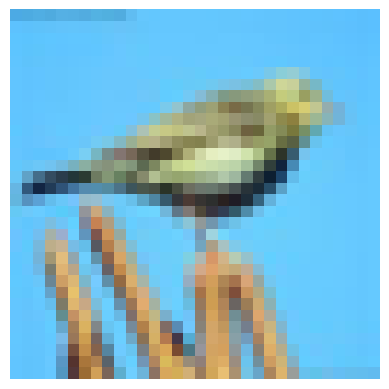

In [25]:
import matplotlib.pyplot as plt
import numpy as np

class_descr = [
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'
]

target_class = "bird"

target_label = np.zeros(len(class_descr))
target_label[class_descr.index(target_class)] = 1

target_instance = np.expand_dims(
    x_test[
        np.argmax(y_test, axis=1)
        == class_descr.index(target_class)
    ][3],
    axis=0
)

print("Shape:", target_instance.shape)

plt.imshow(
    np.transpose(target_instance[0], (1,2,0))
)
plt.axis("off")
plt.show()

In [26]:
pred = classifier.predict(target_instance)

print("Clase real:", target_class)
print(
    "Predicción:",
    class_descr[np.argmax(pred)]
)

Clase real: bird
Predicción: bird


In [27]:
class_descr = [
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'
]

target_class = "bird"

bird_indices = np.where(
    np.argmax(y_test, axis=1)
    == class_descr.index(target_class)
)[0]

print("Número de birds encontrados:", len(bird_indices))
print("Primeros índices:", bird_indices[:10])

Número de birds encontrados: 100
Primeros índices: [ 25  35  65  67  70  75  84  86 113 118]


In [28]:
target_instance = np.expand_dims(
    x_test[bird_indices[3]],
    axis=0
)

print("Shape:", target_instance.shape)

Shape: (1, 3, 32, 32)


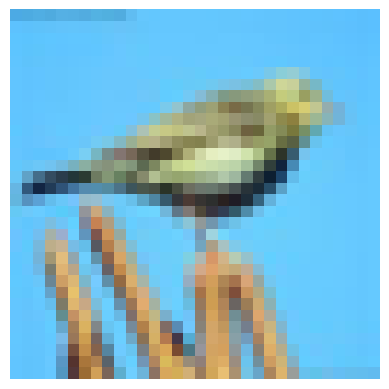

In [29]:
import matplotlib.pyplot as plt

plt.imshow(
    np.transpose(target_instance[0], (1, 2, 0))
)

plt.axis("off")
plt.show()

In [30]:
pred = classifier.predict(target_instance)

print("Clase real: bird")
print(
    "Predicción del modelo:",
    class_descr[np.argmax(pred)]
)

print(
    "Confianza:",
    np.max(pred)
)

Clase real: bird
Predicción del modelo: bird
Confianza: 5.966412


In [31]:
pred = classifier.predict(target_instance)

print(pred.shape)

(1, 10)


In [32]:
base_class = "frog"

base_mask = (
    np.argmax(y_test, axis=1)
    == class_descr.index(base_class)
)

print("Número de frogs:", np.sum(base_mask))

Número de frogs: 112


In [33]:
base_instances = x_test[base_mask][:10]
base_labels = y_test[base_mask][:10]

print("base_instances:", base_instances.shape)
print("base_labels:", base_labels.shape)

base_instances: (10, 3, 32, 32)
base_labels: (10, 10)


In [34]:
x_test_pred = np.argmax(
    classifier.predict(base_instances),
    axis=1
)

nb_correct_pred = np.sum(
    x_test_pred == np.argmax(base_labels, axis=1)
)

print("Correctamente clasificadas:", nb_correct_pred)
print("Incorrectamente clasificadas:", 10 - nb_correct_pred)

Correctamente clasificadas: 9
Incorrectamente clasificadas: 1


In [35]:
feature_layer = "avgpool"

print("Feature layer:", feature_layer)

Feature layer: avgpool


In [36]:
attack = FeatureCollisionAttack(
    classifier=classifier,
    target=target_instance,
    feature_layer=feature_layer,
    max_iter=10,
    similarity_coeff=256,
    watermark=0.3,
    learning_rate=1.0
)

print("Ataque creado correctamente")

Ataque creado correctamente


In [37]:
poison, poison_labels = attack.poison(
    base_instances
)

Feature collision:  10%|█         | 1/10 [00:00<00:00, 21.67it/s]


In [38]:
print("Poison shape:", poison.shape)
print("Poison labels shape:", poison_labels.shape)

Poison shape: (10, 3, 32, 32)
Poison labels shape: (10, 10)


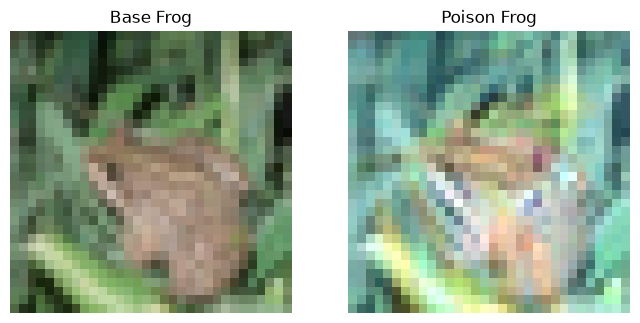

In [39]:
idx = 0

fig, ax = plt.subplots(1,2, figsize=(8,4))

ax[0].imshow(np.transpose(base_instances[idx], (1,2,0)))
ax[0].set_title("Base Frog")
ax[0].axis("off")

ax[1].imshow(np.transpose(poison[idx], (1,2,0)))
ax[1].set_title("Poison Frog")
ax[1].axis("off")

plt.show()

Min: -0.10096982
Max: 0.4697051
Mean abs: 0.1952861


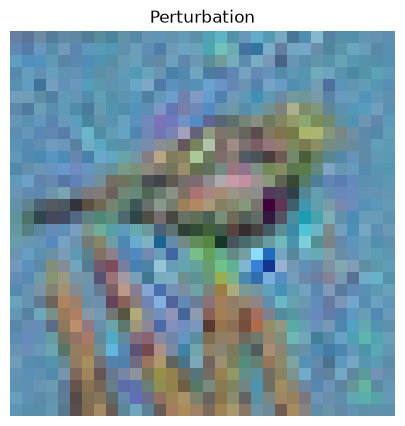

In [40]:
idx = 0

perturbation = poison[idx] - base_instances[idx]

print("Min:", perturbation.min())
print("Max:", perturbation.max())
print("Mean abs:", np.mean(np.abs(perturbation)))

plt.figure(figsize=(5,5))

plt.imshow(
    np.transpose(
        (perturbation - perturbation.min()) /
        (perturbation.max() - perturbation.min()),
        (1,2,0)
    )
)

plt.title("Perturbation")
plt.axis("off")
plt.show()

In [41]:
print(poison.shape)
print(poison_labels.shape)


(10, 3, 32, 32)
(10, 10)


In [42]:
adv_train = np.vstack([
    x_train,
    poison
])

adv_labels = np.vstack([
    y_train,
    poison_labels
])

print("adv_train:", adv_train.shape)
print("adv_labels:", adv_labels.shape)

adv_train: (1010, 3, 32, 32)
adv_labels: (1010, 10)


In [43]:
classifier_model.train()

print("Modo entrenamiento activado")

Modo entrenamiento activado


In [44]:
classifier.fit(
    adv_train,
    adv_labels,
    nb_epochs=20,
    batch_size=4
)


In [45]:
classifier_model.eval()

pred = classifier.predict(target_instance)

pred_class = class_descr[np.argmax(pred)]

print("Clase real:", target_class)
print("Predicción tras el ataque:", pred_class)

Clase real: bird
Predicción tras el ataque: frog


In [46]:
pred = classifier.predict(target_instance)[0]

for i, p in enumerate(pred):
    print(f"{class_descr[i]:10s}: {p:.4f}")

airplane  : -200.2042
automobile: -224.4762
bird      : -47.0101
cat       : 107.8278
deer      : -155.2454
dog       : -78.6253
frog      : 272.3495
horse     : -221.6796
ship      : -222.1608
truck     : -227.2755


In [47]:
pred_class = class_descr[
    np.argmax(
        classifier.predict(target_instance)
    )
]

if pred_class == "frog":

    asr = 100

else:

    asr = 0

print(f"ASR = {asr}%")

ASR = 100%


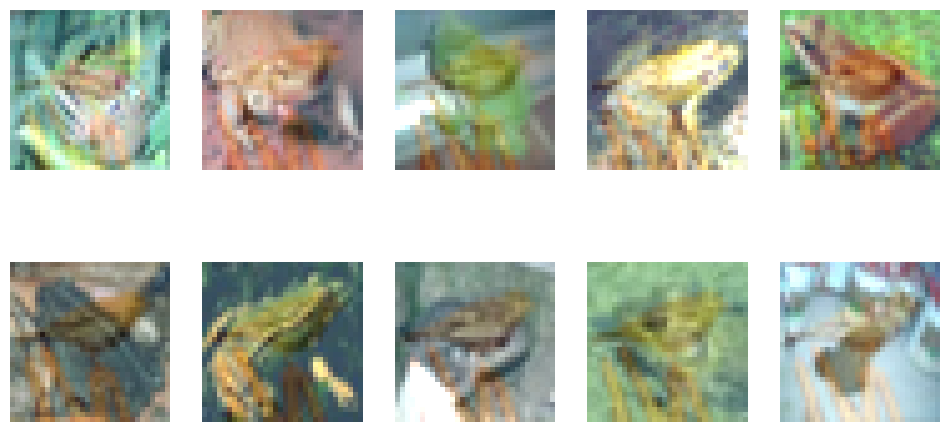

In [48]:
plt.figure(figsize=(12,6))

for i in range(10):

    plt.subplot(2,5,i+1)

    plt.imshow(
        np.transpose(
            poison[i],
            (1,2,0)
        )
    )

    plt.axis("off")

plt.show()

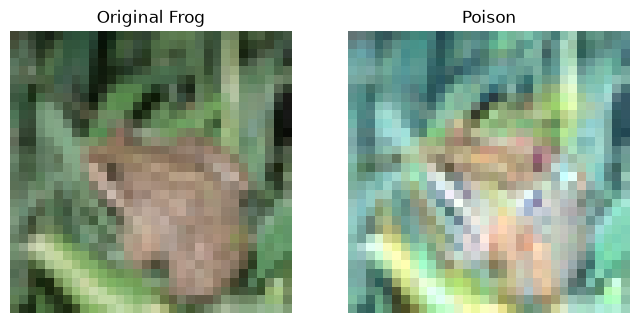

In [49]:
idx = 0

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)

plt.imshow(
    np.transpose(
        base_instances[idx],
        (1,2,0)
    )
)

plt.title("Original Frog")
plt.axis("off")

plt.subplot(1,2,2)

plt.imshow(
    np.transpose(
        poison[idx],
        (1,2,0)
    )
)

plt.title("Poison")
plt.axis("off")

plt.show()

In [50]:
l2 = np.linalg.norm(
    (
        poison -
        base_instances
    ).reshape(10, -1),
    axis=1
)

print("Perturbación L2 media:", np.mean(l2))
print("Perturbación L2 máxima:", np.max(l2))

Perturbación L2 media: 11.4967375
Perturbación L2 máxima: 11.669837


In [51]:
pred_test = np.argmax(
    classifier.predict(x_test),
    axis=1
)

true_test = np.argmax(
    y_test,
    axis=1
)

acc = np.mean(
    pred_test == true_test
)

print("Accuracy:", acc)

Accuracy: 0.631


In [52]:
print("===== RESUMEN =====")
print("Target:", target_class)
print("Clase base:", base_class)
print("Número de venenos:", len(poison))
print("Feature layer:", feature_layer)
print("Predicción final:", pred_class)
print("ASR:", asr, "%")

===== RESUMEN =====
Target: bird
Clase base: frog
Número de venenos: 10
Feature layer: avgpool
Predicción final: frog
ASR: 100 %


In [53]:
pred_test = np.argmax(
    classifier.predict(x_test),
    axis=1
)

true_test = np.argmax(
    y_test,
    axis=1
)

for i, clase in enumerate(class_descr):

    mask = (true_test == i)

    acc_clase = np.mean(
        pred_test[mask] == true_test[mask]
    )

    print(
        f"{clase:10s}: {acc_clase:.3f}"
    )

airplane  : 0.631
automobile: 0.876
bird      : 0.510
cat       : 0.534
deer      : 0.544
dog       : 0.419
frog      : 0.777
horse     : 0.716
ship      : 0.726
truck     : 0.550


In [54]:
# ==========================================
# GUARDAR RESULTADOS MODELO ENVENENADO
# ==========================================

pred_test_poisoned = np.argmax(
    classifier.predict(x_test),
    axis=1
)

acc_poisoned = np.mean(
    pred_test_poisoned == true_test
)

pred_target_poisoned = class_descr[
    np.argmax(
        classifier.predict(target_instance)
    )
]

print("Accuracy envenenada:", acc_poisoned)
print("Target envenenado:", pred_target_poisoned)

Accuracy envenenada: 0.631
Target envenenado: frog


In [55]:
# ============================================================
# EVALUACIÓN DEL MODELO ORIGINAL (SIN VENENO)
# ============================================================

# Recargar modelo original
classifier_model_clean = resnet18(pretrained=False)

classifier_model_clean.load_state_dict(
    torch.load(
        "resnet18.pt",
        map_location="cpu"
    )
)

classifier_model_clean.eval()

# Reconstruir clasificador ART limpio
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    classifier_model_clean.parameters(),
    lr=1e-4
)

classifier_clean = PyTorchClassifier(
    model=classifier_model_clean,
    clip_values=(min_, max_),
    loss=criterion,
    optimizer=optimizer,
    input_shape=(3,32,32),
    nb_classes=10,
    preprocessing=(
        (0.4914,0.4822,0.4465),
        (0.2471,0.2435,0.2616)
    )
)

# Accuracy global
pred_test_clean = np.argmax(
    classifier_clean.predict(x_test),
    axis=1
)

true_test = np.argmax(
    y_test,
    axis=1
)

acc_clean = np.mean(
    pred_test_clean == true_test
)

print("=" * 50)
print("MODELO LIMPIO")
print("=" * 50)
print("Accuracy:", acc_clean)

# Accuracy por clase
print("\nAccuracy por clase:")

for i, clase in enumerate(class_descr):

    mask = (true_test == i)

    acc_clase = np.mean(
        pred_test_clean[mask] == true_test[mask]
    )

    print(
        f"{clase:10s}: {acc_clase:.3f}"
    )

# Predicción sobre el target original
pred_target_clean = classifier_clean.predict(
    target_instance
)

print("\nPredicción del target con modelo limpio:")
print(
    class_descr[
        np.argmax(pred_target_clean)
    ]
)

# ============================================================
# COMPARACIÓN LIMPIO vs ENVENENADO
# ============================================================

print("\n" + "=" * 50)
print("COMPARACIÓN FINAL")
print("=" * 50)

print("Accuracy limpia      :", acc_clean)
print("Accuracy envenenada  :", acc)

print(
    "Target modelo limpio :",
    class_descr[np.argmax(pred_target_clean)]
)

print(
    "Target envenenado    :",
    pred_class
)

print("ASR                  :", asr, "%")

MODELO LIMPIO
Accuracy: 0.917

Accuracy por clase:
airplane  : 0.903
automobile: 0.966
bird      : 0.910
cat       : 0.796
deer      : 0.922
dog       : 0.849
frog      : 0.955
horse     : 0.971
ship      : 0.953
truck     : 0.936

Predicción del target con modelo limpio:
bird

COMPARACIÓN FINAL
Accuracy limpia      : 0.917
Accuracy envenenada  : 0.631
Target modelo limpio : bird
Target envenenado    : frog
ASR                  : 100 %
